In [1]:
# Một số thư viện cần có
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

# Câu hỏi 1
## Phát biểu câu hỏi
Trong mạng lưới hàng ngàn nhà cung cấp của Thành phố Boulder, dòng tiền giải ngân đang được phân bổ đồng đều hay bị thâu tóm bởi một nhóm thiểu số hay một nhà thầu nào đó? Liệu hệ thống tài chính của thành phố có đang gặp rủi ro phụ thuộc vào một vài 'ông lớn' (cá mập), và sự chênh lệch về vị thế tài chính giữa nhóm thống trị này so với đại đa số nhà thầu lặt vặt thực sự sâu sắc đến mức nào?

---

Dựa vào các mô tả dataset ở [link này](https://open-data.bouldercolorado.gov/datasets/Boulder::accounts-payable-current/about?fbclid=IwY2xjawViePtleHRuA2FlbQIxMQBwZG9mBHNydGMGYXBwX2lkATAAAR8VADwXVJN5QKQ8QpY6BqBqTV2UBvuCcbtP8Qu1RVTBOohQnlLAkpTtHB5eBw_aem_ybpJDNv8J6iU2Tmses0ibw), ta thấy được bản chất câu hỏi xoay quanh qua 2 trường là `vendor_name` và `transaction_amount`. Trước hết, ta cần phải biết xem có gì đặc biệt ở hai trường thuộc tính này không? Cụ thể hơn, để có thể khảo sát được, ta phải đảm bảo được hai trường thuộc tính này không bị thiếu giá trị, hay có những giá trị lỗi.

In [2]:
# 1. Tải và lọc dữ liệu
df = pd.read_csv('Accounts_Payable_Current.csv')
df['transaction_date'] = pd.to_datetime(df['transaction_date'], errors='coerce')
df_valid = df[(df['transaction_date'].dt.year >= 2023) & 
              (df['transaction_date'].dt.year <= 2025) & 
              (df['transaction_amount'] > 0)].copy()

# 2. Khảo sát Missing Values
missing_vendors = df_valid['vendor_name'].isna().sum()
print(f"Số lượng giao dịch trống Tên nhà thầu: {missing_vendors}")

# 3. Chuẩn bị dữ liệu tính toán
df_valid = df_valid.dropna(subset=['vendor_name'])
total_spend = df_valid['transaction_amount'].sum()
vendor_totals = df_valid.groupby('vendor_name')['transaction_amount'].sum().sort_values(ascending=False)

Số lượng giao dịch trống Tên nhà thầu: 0


Có vẻ như không tồn tại thuộc tính nào bị thiếu giá trị, tới đây ta có thể yên tâm mà thực hiện khảo sát của mình. Quay trở lại câu hỏi, ta cần làm rõ liệu rằng có dấu hiệu nào cho thấy việc ngân sách của Thành phố Boulder có dấu hiệu bị "chiếm độc quyền hay không". Để thực hiện điều đó, bước đi tự nhiên nhất là thử gom nhóm toàn bộ dữ liệu theo từng nhà thầu, tính tổng số tiền giải ngân họ nhận được và xếp hạng từ cao xuống thấp.

In [3]:
# Gom nhóm theo nhà thầu, tính tổng số tiền và xếp hạng giảm dần
vendor_totals = df_valid.groupby('vendor_name')['transaction_amount'].sum().sort_values(ascending=False)
total_spend = df_valid['transaction_amount'].sum()
total_vendors = len(vendor_totals)

print(f"Tổng số nhà thầu trong hệ thống: {total_vendors:,.0f}")
print(f"Tổng ngân sách giải ngân: ${total_spend:,.2f}\n")
print("--- TOP 10 NHÀ THẦU NHẬN GIẢI NGÂN LỚN NHẤT ---")
print(vendor_totals.head(10).apply(lambda x: f"${x:,.2f}"))

Tổng số nhà thầu trong hệ thống: 2,332
Tổng ngân sách giải ngân: $323,562,521.00

--- TOP 10 NHÀ THẦU NHẬN GIẢI NGÂN LỚN NHẤT ---
vendor_name
Saunders Construction Inc         $29,326,666.57
Garney Companies Inc              $20,146,291.75
Native Sun Materials Inc          $12,951,284.29
Mile High Flood District          $11,352,000.00
PCL Construction, Inc              $8,738,111.80
Gillig LLC                         $8,183,135.00
Motorola Solutions Inc             $7,759,552.91
BT Construction Inc                $7,604,150.93
Front Range Fire Apparatus LTD     $5,505,844.89
Concrete Works of Colorado Inc     $5,276,083.83
Name: transaction_amount, dtype: object


Chỉ cần nhìn lướt qua kết quả top 10, ta thấy được sự chênh lệch khá rõ ràng. Các nhà thầu đứng đầu nhận được hàng chục triệu đô la, và sự chênh lệch giữa các nhà thầu khá rõ ràng (nhà thầu đứng thứ 2 chênh gần 9 triệu đô la so với nhà thầu đầu tiên). Điều này thể hiện sự chênh lệch cực độ, bởi lẽ có tới hàng ngàn nhà thầu tham gia.

Để nhìn rõ hơn toàn cảnh sự phân bổ này thay vì chỉ tập trung vào phần ngọn, ta sẽ tính toán tỷ lệ phần trăm tích lũy của cả dòng tiền lẫn số lượng nhà thầu. Trong bước này, mục đích của ta là làm rõ xem các nhà thầu top đầu (như đã khảo sát ở trên) thực sự chiếm bao nhiêu phần trăm ngân sách

In [4]:
# --- Khảo sát sự phân bổ ngân sách (Tích lũy dòng tiền) ---
# Tính % tích lũy của nhà thầu và % tích lũy của số tiền
vendor_pct = np.arange(1, len(vendor_totals) + 1) / len(vendor_totals) * 100
spend_cumsum = vendor_totals.cumsum() / total_spend * 100

# Khảo sát thử ở các mốc 5%, 10% và 20% số lượng nhà thầu
check_points = [0.05, 0.10, 0.20]
print("--- KHẢO SÁT TÍCH LŨY DÒNG TIỀN ---")
for cp in check_points:
    idx = int(len(vendor_totals) * cp)
    print(f"Top {cp*100:2.0f}% nhà thầu lớn nhất đang nắm giữ {spend_cumsum.iloc[idx]:.2f}% tổng ngân sách.")

--- KHẢO SÁT TÍCH LŨY DÒNG TIỀN ---
Top  5% nhà thầu lớn nhất đang nắm giữ 80.69% tổng ngân sách.
Top 10% nhà thầu lớn nhất đang nắm giữ 88.37% tổng ngân sách.
Top 20% nhà thầu lớn nhất đang nắm giữ 94.39% tổng ngân sách.


Kết quả trên đã cho thấy sự chênh lệch cực kỳ lớn đó là chỉ mới top 5% nhà thầu đầu tiên đã thâu tóm phần lớn ngân sách, và top 20% gần như chiếm toàn bộ dòng tiền của thành phố.

### Nguyên lý Pareto (80/20)
Nguyên lý Pareto cho rằng: _Khoảng 80% kết quả thường đến từ 20% nguyên nhân hoặc nỗ lực quan trọng nhất._ Ý nghĩa của nguyên lý là không phải mọi công việc, nguyên nhân hay nguồn lực đều có giá trị như nhau. Một số ít yếu tố quan trọng thường tạo ra phần lớn kết quả. 

Ở trong tình huống này, nhóm sẽ áp dụng nguyên lý Pareto được đề cập ở trên để khảo sát. Nhóm muốn tìm xem chính xác cần bao nhiêu phần trăm nhà thầu để chiếm đúng mốc 80% ngân sách. Việc này nhằm kiểm chứng xem sự khắc nghiệt của tập dữ liệu giải ngân công này có thực sự vượt qua ranh giới 80/20 hay không.

In [5]:
# --- Áp dụng tư duy Pareto: Tìm điểm cắt đúng 80% ngân sách ---
pareto_idx = np.argmax(spend_cumsum >= 80)
pareto_vendor_pct = vendor_pct[pareto_idx]

print(f"--- KIỂM CHỨNG ĐỊNH LUẬT PARETO ---")
print(f"Thực tế: Chỉ cần {pareto_vendor_pct:.2f}% số lượng nhà thầu đã thâu tóm tới 80% tổng ngân sách!")

--- KIỂM CHỨNG ĐỊNH LUẬT PARETO ---
Thực tế: Chỉ cần 4.80% số lượng nhà thầu đã thâu tóm tới 80% tổng ngân sách!


Kết quả Pareto cho thấy sự bất bình đẳng tột độ. Cụ thể hơn, tình huống này còn mất cân bằng mạnh hơn nhiều so với nguyên lý Pareto được dùng để đối chiếu. Ta thấy được chỉ cần 4.8% số lượng nhà thầu đã thầu tóm tới 80% tổng ngân sách. Điều này ám chỉ rằng, có vẻ hiện tượng bất bình đẳng (có nhà thầu chiếm được nhiều ngân sách hơn) đang có xảy ra. Tuy nhiên, mục đích của câu hỏi này là làm rõ liệu rằng có tồn tại sự "độc chiếm" nào xảy ra ở đây không? 

Để trả lời điều này, ta phải tiếp tục khảo sát chi tiết tỷ trọng (thị phần - market share) của từng nhà thầu trong top đầu trên tổng ngân sách.

In [6]:
# --- Khảo sát thị phần của các nhà thầu lớn nhất ---
# Tính phần trăm thị phần cho từng nhà thầu
market_shares = (vendor_totals / total_spend) * 100

print("--- KHẢO SÁT THỊ PHẦN TOP 5 NHÀ THẦU ---")
print(market_shares.head(5).apply(lambda x: f"{x:.2f}%"))

--- KHẢO SÁT THỊ PHẦN TOP 5 NHÀ THẦU ---
vendor_name
Saunders Construction Inc    9.06%
Garney Companies Inc         6.23%
Native Sun Materials Inc     4.00%
Mile High Flood District     3.51%
PCL Construction, Inc        2.70%
Name: transaction_amount, dtype: object


Kết quả cho thấy nhà thầu lớn nhất (Saunders Construction Inc) chỉ chiếm chưa tới 10% tổng ngân sách. Không có một doanh nghiệp nào chiếm thế lũng đoạn tuyệt đối (từ 40% - 50%). Dù cảm quan là vậy, nhưng để đưa ra kết luận chính thức, ta không thể dùng cảm tính được. Ta sẽ cần một thước đo định lượng chuẩn mực của kinh tế học vĩ mô và luật chống độc quyền.

### Chỉ số HHI (Herfindahl-Hirschman Index)
Đây là một chỉ số dùng để đo lường mức độ tập trung của thị trường, doanh thu, ngân sách hoặc bất kỳ nguồn lực nào được phân bố giữa nhiều đối tượng.
#### Công thức
$$
HHI = \sum_{i = 1}^{n} s_i^2
$$
Trong đó:
- $s_i$ là thị phần (hoặc tỷ trọng ngân sách) của đối tượng thứ $i$ tính theo phần trăm (%).
- $HHI$ bằng tổng bình phương các tỷ trọng.

Đây là công cụ được Bộ Tư pháp Mỹ (DOJ) sử dụng để phán xử mức độ lũng đoạn thị trường bằng cách tính tổng bình phương thị phần của tất cả các bên tham gia. Mốc tham chiếu rất rõ ràng:
- $HHI < 1500:$ Thị trường phân mảnh, cạnh tranh tốt.
- $HHI$ từ $1500 - 2500$: Tập trung vừa phải.
- $HHI > 2500$: Cảnh báo rủi ro độc quyền cao độ. 

In [7]:
# --- Tính toán Chỉ số HHI (Đo lường mức độ độc quyền) ---
# HHI = Tổng bình phương của tất cả các thị phần
hhi = (market_shares ** 2).sum()

print(f"--- ĐÁNH GIÁ RỦI RO ĐỘC QUYỀN (HHI) ---")
print(f"Chỉ số HHI của hệ thống = {hhi:.2f} điểm")

--- ĐÁNH GIÁ RỦI RO ĐỘC QUYỀN (HHI) ---
Chỉ số HHI của hệ thống = 214.37 điểm


Ta thấy được rằng HHI chỉ ở mức hơn 200 điểm (so với mốc 1500), điều này cho thấy rằng hệ thống đấu thầu của thành phố Boulder không xảy ra hiện tượng độc chiếm ngân sách nào cả. Từ đây mọi thứ dần rõ ràng hơn, từ nguyên lý Pareto và chỉ số HHI, ta thấy được mạng ưới cung ứng đang bị chia cắt thành hai nhóm: thiểu số "cá mập" (chiếm 5% nhưng chia nhau 80% doanh thu), và 95% "cá con" chia nhau những khoản lẻ tẻ.

Nhóm quyết định chia tách dữ liệu thành 2 thế giới này để khảo sát xem: Quy mô mỗi lần giải ngân (từng hóa đơn) của 2 nhóm này thực sự chênh lệch ra sao?

In [8]:
# --- Khảo sát quy mô hóa đơn giữa 2 thế giới (Cá mập vs Cá con) ---
# Xác định điểm cắt 5% số lượng nhà thầu
top_5_pct_idx = int(len(vendor_totals) * 0.05)

# Trích xuất danh sách tên nhà thầu
top_vendors = vendor_totals.head(top_5_pct_idx).index
bottom_vendors = vendor_totals.tail(len(vendor_totals) - top_5_pct_idx).index

# Lấy chi tiết toàn bộ các hóa đơn của 2 nhóm
top_txns = df_valid[df_valid['vendor_name'].isin(top_vendors)]['transaction_amount']
bottom_txns = df_valid[df_valid['vendor_name'].isin(bottom_vendors)]['transaction_amount']

print(f"--- SO SÁNH QUY MÔ HÓA ĐƠN TRUNG BÌNH ---")
print(f"Hóa đơn trung bình của Nhóm Cá mập (Top 5%): ${top_txns.mean():,.2f}")
print(f"Hóa đơn trung bình của Nhóm Cá con (95%): ${bottom_txns.mean():,.2f}")

--- SO SÁNH QUY MÔ HÓA ĐƠN TRUNG BÌNH ---
Hóa đơn trung bình của Nhóm Cá mập (Top 5%): $28,652.06
Hóa đơn trung bình của Nhóm Cá con (95%): $2,471.34


Sự chênh lệch là khá rõ ràng, hai nhóm có hóa đơn trung bình trên lệch tới hàng chục nghìn đô la. Nhưng bây giờ ta cần phải tìm cách để khẳng định khoảng cách này là một bản chất cố hữu của hệ thống tài chính, chứ không phải do sự may rủi ngẫu nhiên của tập mẫu? Hay nói cách khác, ta cần các kiểm định đánh giá.

Ý tưởng đầu tiên của nhóm là chạy kiểm định T-test (Student's t-test) để so sánh hai giá trị trung bình. Tuy nhiên, khi nhìn lại đặc trưng của tập dữ liệu `Accounts_Payable` từ đầu đến giờ, ta biết rằng cột số tiền luôn bị lệch phải cực đoan với sự xuất hiện của những hóa đơn có thể gọi là "siêu dự án". Dữ liệu này vi phạm nghiêm trọng giả định phân phối chuẩn của T-test. Do đó nếu dùng T-test, kết quả sẽ bị sai lệch toán học nặng nề. 

Đứng trước bài toán này, nhóm quyết định đổi chiến thuật, tìm đến các công cụ phi tham số (non-parametric) "chống đạn" tốt hơn với các giá trị ngoại lai khổng lồ:

### 1. Kỹ thuật Bootstrap Confidence Interval (CI 95%)
Đây là một phương pháp lấy mẫu lại (resampling) hiện đại trong thống kê suy diễn. Thay vì dựa vào các giả định toán học cố định (như phân phối chuẩn), Bootstrap tạo ra hàng ngàn tập dữ liệu "ảo" bằng cách bốc ngẫu nhiên có hoàn lại (sampling with replacement) từ chính tập dữ liệu gốc. Sau đó, nó tính toán giá trị trung bình trên từng tập ảo này để xây dựng một dải phân phối mới.

Lý do nhóm chọn kỹ thuật này là vì tập hóa đơn của nhóm "cá mập" có sự xuất hiện của các siêu hợp đồng, mức trung bình thô có thể bị kéo vọt lên. Bootstrap giúp ta khoanh vùng một khoảng tin cậy 95%, nghĩa là ta có thể tự tin 95% rằng "quy mô hóa đơn trung bình thực sự của nhóm cá mập chắc chắn nằm trong khoảng từ $A$ đến $B$".

### 2. Kiểm định Mann-Whitney U Test (???)
Đây là một kiểm định thống kê phi tham số dùng để so sánh hai quần thể độc lập. Khác với T-test so sánh dựa trên giá trị trung bình (mean), Mann-Whitney U Test gom toàn bộ dữ liệu của hai nhóm lại, sắp xếp từ nhỏ đến lớn, rồi gán "thứ hạng" (rank) cho từng giá trị. Cuối cùng, nó so sánh tổng thứ hạng của hai nhóm để xem có sự chênh lệch đáng kể nào không.

Việc dùng "thứ hạng" thay vì "số tiền thực tế" giúp kiểm định này hoàn toàn miễn nhiễm trước các siêu dự án. Một hóa đơn 10 triệu USD hay 100 triệu USD thì cũng chỉ được tính là "hạng 1", không làm sai lệch kết quả. Nó trả về giá trị $p\text{-value}$: Nếu $p\text{-value} < 0.05$, ta có quyền bác bỏ giả thuyết không (Null Hypothesis) và khẳng định rằng quy mô hóa đơn giữa "Cá mập" và "Cá con" là hoàn toàn khác biệt về mặt bản chất. Ta có thể tính $p\text{-value}$ thông qua hàm `stats.mannwhitneyu()` trong thư viện SciPy.

In [9]:
# --- Kiểm định thống kê chống nhiễu (Robust Statistics) ---
# 1. Chạy kiểm định Mann-Whitney U
stat, p_val = stats.mannwhitneyu(top_txns, bottom_txns, alternative='two-sided')
print("--- KIỂM ĐỊNH MANN-WHITNEY U ---")
print(f"P-value = {p_val:.5e}")

# 2. Tính Bootstrap CI 95% để lượng hóa khoảng tin cậy cho nhóm Cá mập
np.random.seed(42) # Cố định seed để tái lập kết quả
# Rút ngẫu nhiên 1000 tập mẫu phụ từ nhóm Cá mập và tính mean
bootstrap_means = [np.mean(np.random.choice(top_txns, size=len(top_txns), replace=True)) for _ in range(1000)]
ci_lower, ci_upper = np.percentile(bootstrap_means, [2.5, 97.5])

print("\n--- KHOẢNG TIN CẬY BOOTSTRAP 95% ---")
print(f"Hóa đơn trung bình của Top 5% Nhà thầu thực tế nằm trong khoảng: [${ci_lower:,.2f} , ${ci_upper:,.2f}]")

--- KIỂM ĐỊNH MANN-WHITNEY U ---
P-value = 8.00481e-70

--- KHOẢNG TIN CẬY BOOTSTRAP 95% ---
Hóa đơn trung bình của Top 5% Nhà thầu thực tế nằm trong khoảng: [$24,829.09 , $33,162.70]


Mọi phép toán đã hoàn tất với $p-value$ tiệm cận 0. Để gói gọn toàn bộ luồng phân tích trên thành một góc nhìn trực quan và quyền lực nhất, nhóm sử dụng Đường cong Lorenz (Lorenz Curve). Đây là biểu đồ kinh điển trong kinh tế học dùng để miêu tả sự bất bình đẳng, hiển thị phần trăm tích lũy của dòng tiền bị kéo lệch như thế nào so với một thế giới hoàn hảo (đường phân bổ bình đẳng tuyệt đối).

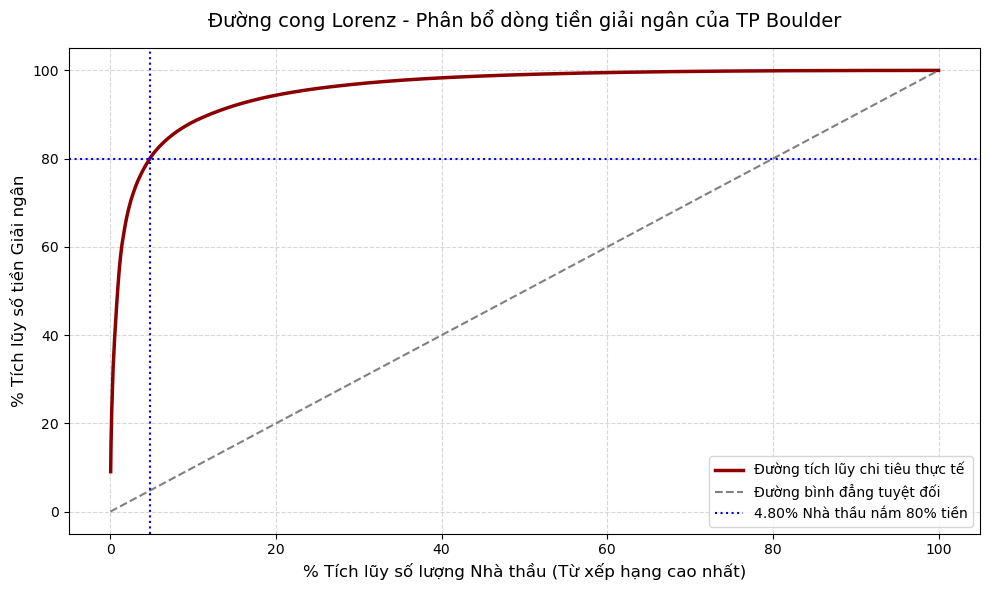

In [10]:
# --- Tổng kết trực quan bằng Đường cong Lorenz ---
plt.figure(figsize=(10, 6))

# Vẽ đường phân bổ thực tế của thành phố
plt.plot(vendor_pct, spend_cumsum, color='darkred', linewidth=2.5, label='Đường tích lũy chi tiêu thực tế')

# Vẽ đường bình đẳng (nếu mọi nhà thầu đều nhận số tiền như nhau)
plt.plot([0, 100], [0, 100], color='gray', linestyle='--', label='Đường bình đẳng tuyệt đối')

# Điểm nhấn định luật Pareto
plt.axvline(x=pareto_vendor_pct, color='blue', linestyle=':', label=f'{pareto_vendor_pct:.2f}% Nhà thầu nắm 80% tiền')
plt.axhline(y=80, color='blue', linestyle=':')

# Trang trí biểu đồ
plt.title('Đường cong Lorenz - Phân bổ dòng tiền giải ngân của TP Boulder', fontsize=14, pad=15)
plt.xlabel('% Tích lũy số lượng Nhà thầu (Từ xếp hạng cao nhất)', fontsize=12)
plt.ylabel('% Tích lũy số tiền Giải ngân', fontsize=12)
plt.legend(loc='lower right', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Trước hết, ta cần phải hiểu rõ biểu đồ này:
- Trục $X$ thể hiện phần trăm cộng dồn số lượng các nhà cung cấp/nhà thầu được sắp xếp theo nhóm có nhiều ngân sách nhất đến nhóm có ít ngân sách nhất.
- Trục $Y$ thể hiện phần trăm cộng dồn giá trị ngân sách thực tế mà các nhà thầu đó nhận được trên tổng ngân sách của toàn thành phố.
- Vạch nét đứt màu xám (đường bình đẳng tuyệt đối) đại diện cho thế giới "lý tưởng", mà ở đó $k\%$ số nhà thầu sẽ nhận được $k\%$ số ngân sách.

Từ đây ta có một nhận xét với biểu đồ trên như sau:
- **Độ lệch khỏi mức bình đẳng lý tưởng**: Đường tích lũy chi tiêu thực tế lại tách rời hoàn toàn và nằm hoàn toàn lên phía trên cùng. Khoảng cách khổng lồ giữa đường màu đỏ và đường nét đứt xám chính là "diện tích của sự bất bình đẳng".
- **Sức mạnh lấn át ở giai đoạn đầu**: Ta thấy đường cong màu đỏ phóng thẳng đứng lên trên chỉ trong một đoạn rất ngắn ở ngay vạch xuất phát. Điều này trực quan hóa sức hút tiền khổng lồ của một nhóm thiểu số các nhà thầu lớn ở vị trí top đầu.
- **Phá vỡ giới hạn Pareto**: Giao điểm của hai đường nét đứt màu xanh, đáng lẽ phải nằm ở vị trí (20, 80) (hoặc xấp xỉ gần đó) theo nguyên lý Pareto. Tuy nhiên ở đây giao điểm trên đã lùi sát về trục tung. Hay nói cách khác, chỉ đúng 4.80% số lượng nhà thầu đầu bảng đã nắm trọn 80% tổng dòng tiền giải ngân của toàn thành phố. Đoạn đường cong kéo dài từ mốc 4.80% dãn ra đến tận 100% gần như đi ngang, phản ánh thực trạng của hàng ngàn nhà cung cấp "cá con" xếp phía sau — dù đông đảo về số lượng (chiếm hơn 95%) nhưng chỉ được chia nhau 20% lượng ngân sách ít ỏi còn sót lại.

## Kết luận
Qua quá trình đi từng bước khảo sát, và xác thực bằng các định lượng thống kê, bức tranh mạng lưới nhà thầu của Thành phố Boulder có 3 điểm nổi bật sau:
- **Sự tập trung cực đoan**: Dữ liệu chứng minh rằng sự bất bình đẳng ở đây khắc nghiệt hơn cả mức 80/20 thông thường (vượt xa nguyên lý Pareto). Chỉ với chưa tới 5% số lượng nhà thầu, họ đã thâu tóm trọn vẹn 80% tổng ngân sách. Đường cong Lorenz vút lên gần như thẳng đứng ở vạch đích đã trực quan hóa sức hút khổng lồ của nhóm thiểu số này.
- **Không có sự thâu tóm độc quyền**: Mặc dù phần lớn ngân sách nằm trong tay một nhóm thiểu số, chỉ số HHI lại chỉ đạt hơn 200 điểm — thấp hơn rất nhiều so với ngưỡng rủi ro 1500 của DOJ. Điều này kết luận rằng thành phố không rơi vào sự thâu tóm độc quyền ngân sách của một cá nhân nào. Bản chất thị trường là một nhóm các nhà thầu lớn mạnh cùng nhau thi công các dự án khổng lồ, tạo ra sự phân hóa chứ không lũng đoạn toàn quyền.
- **Hai thế giới song song**: Kết quả $p-value \approx 0$ từ kiểm định phi tham số Mann-Whitney và khoảng tin cậy Bootstrap chứng minh mạnh mẽ rằng khoảng cách quy mô giữa nhóm "cá mập" và nhóm "cá con" là bản chất cố hữu của hệ thống tài chính này. Nhóm 95% nhà cung cấp dưới đáy thực chất chỉ đóng vai trò bán lẻ các vật tư vận hành lặt vặt hàng ngày cho bộ máy chính quyền.

# Câu hỏi 2
## Phát biểu câu hỏi
Sự thống trị ngân sách của các phòng ban top đầu (như Utilities, Facilities & Fleet, Transportation) là do chi phí vận hành cốt lõi hàng ngày, hay thực chất chỉ là "ảo ảnh" gây ra bởi một vài siêu dự án hạ tầng đột biến? Xếp hạng quyền lực ngân sách của các phòng ban này có thực sự vững (robust) khi ta kiểm soát và loại bỏ sức nặng của các hợp đồng ngoại lai khổng lồ?

---
Để trả lời câu hỏi này, trước tiên ta cần phải xác định xem phòng ban (department) nào đang tiêu nhiều tiền nhất dựa trên bề nổi của dữ liệu. Hay nói cách khác, ta phải khảo sát 2 trường `department` và `transaction_amount`. Tuy nhiên, trước hết ta phải khảo sát hai trường này xem liệu rằng có các lỗi như thiếu thông tin hay gì không? Nếu có, ta phải loại bỏ chúng để tránh ngân sách bị tính hụt.

In [11]:
# --- 1. Khảo sát Missing Values ở cột Phòng ban ---
missing_depts = df_valid['department'].isna().sum()
print(f"Số lượng giao dịch bị trống thông tin Phòng ban: {missing_depts}")

Số lượng giao dịch bị trống thông tin Phòng ban: 483


Có vẻ như có tới tận 483 giao dịch bị trống thông tin phòng ban. Do đó, ta phải loại bỏ chúng.

In [12]:
df_valid = df_valid.dropna(subset=['department'])
missing_depts = df_valid['department'].isna().sum()
print(f"Số lượng giao dịch bị trống thông tin Phòng ban: {missing_depts}")

Số lượng giao dịch bị trống thông tin Phòng ban: 0


Tuyệt vời, bây giờ ta sẽ thực hiện khảo sát chúng. Ta sẽ xếp hạng các phòng ban bằng phép tính tổng (`sum`) thông thường.

In [13]:
# --- 2. Khảo sát bề nổi: Bảng xếp hạng Base Sum ---
# Tính tổng ngân sách theo từng phòng ban và xếp hạng giảm dần
rank_base = df_valid.groupby('department')['transaction_amount'].sum().sort_values(ascending=False)

print("\n--- TOP 10 PHÒNG BAN CHI TIÊU NHIỀU NHẤT (TÍNH TỔNG THÔ) ---")
print(rank_base.head(10).apply(lambda x: f"${x:,.2f}"))


--- TOP 10 PHÒNG BAN CHI TIÊU NHIỀU NHẤT (TÍNH TỔNG THÔ) ---
department
Utilities                        $89,900,643.28
Facilities and Fleet             $83,943,847.27
Transportation and Mobility      $41,919,030.91
Housing and Human Services       $20,655,154.30
Fundwide / Citywide              $18,292,691.25
Open Space and Mountain Parks    $12,429,764.43
Community Vitality                $8,921,098.18
Innovation and Technology         $8,756,389.73
Parks and Recreation              $8,442,978.67
Finance                           $7,199,641.89
Name: transaction_amount, dtype: object


Dựa vào bảng xếp hạng tổng thô ở trên, Sở Utilities, Sở Facilities and Fleet và Sở Transportation đang chễm chệ ở những vị trí dẫn đầu. 

Tuy nhiên, trong phân tích tài chính công, việc tính tổng hay lấy giá trị trung bình cực kỳ "nhạy cảm" với các giá trị ngoại biên (outliers). Một số dự án có số lượng tiền khổng lồ của một Sở có thể làm thay đổi chi phí của hàng ngàn hóa đơn nhỏ khác. Do đó, để kiếm chứng sự "thống trị" của các Sở này, ta phải khảo sát phân phối của toàn bộ của hóa đơn trên hệ thống.

In [18]:
# --- 3. Khảo sát đặc trưng phân phối của dòng tiền ---
print("--- THỐNG KÊ MÔ TẢ QUY MÔ HÓA ĐƠN ---")
# Dùng hàm float format để tránh hiển thị số thực dạng khoa học (e.g., 1.5e7)
print(df_valid['transaction_amount'].describe().apply(lambda x: f"${x:,.2f}"))

--- THỐNG KÊ MÔ TẢ QUY MÔ HÓA ĐƠN ---
count        $34,040.00
mean          $9,386.30
std         $107,401.06
min               $0.04
25%              $88.16
50%             $384.00
75%           $1,874.75
max      $11,000,000.00
Name: transaction_amount, dtype: object


Kết quả trên cho thấy rằng dòng tiền bị lệch phải một cách cực đoan. Cụ thể, mức chi tiêu trung vị (50% hóa đơn) chỉ nằm ở mức vài 384 đô, và mức 75% hóa đơn cũng chỉ nằm ở mức gần 1874 đô. Thế nhưng, giá trị max lại tăng lên tới 11 triệu đô. Từ hiện tượng này, ta thấy có vẻ có tồn tại các "siêu dự án" làm nhiễu bức tranh vận hành cốt lõi của thành phố.

### Kỹ thuật Robustness Check
Kỹ thuật này sẽ đánh giá sự biến động thứ hạng của các phòng ban qua 3 kịch bản với độ "chống nhiễu" tăng dần:
- **Kịch bản 1 (base case)**: Xếp hạng dựa trên tổng thô (như đã tính ở phần trên).
- **Kịch bản 2 (trimmed sum)**: Xác định ngưỡng 99% (loại bỏ 1% các siêu hóa đơn khổng lồ nhất hệ thống) và tính lại tổng. Kịch bản này mô phỏng bức tranh thành phố khi không có các cú sốc hạ tầng đột biến.
- **Kịch bản 3 (median base)**: Xếp hạng các phòng ban hoàn toàn dựa trên giá trị trung vị (median). Trung vị là thước đo miễn nhiễm hoàn toàn với các siêu dự án, phản ánh chính xác quy mô của những hóa đơn diễn ra thường nhật nhất tại mỗi Sở.

In [15]:
# --- 4. Thực hiện Kiểm tra tính vững (Robustness Check) ---

# Kịch bản 2 (Trimmed Sum): Xác định điểm cắt 99% để lọc "Siêu dự án"
threshold_99 = df_valid['transaction_amount'].quantile(0.99)
print(f"Ngưỡng Siêu dự án (Top 1% hóa đơn lớn nhất): > ${threshold_99:,.2f}\n")

# Lọc bỏ top 1% này
df_trimmed = df_valid[df_valid['transaction_amount'] <= threshold_99]
# Xếp hạng lại theo tổng đã cắt tỉa
rank_trimmed = df_trimmed.groupby('department')['transaction_amount'].sum().sort_values(ascending=False)

# Kịch bản 3 (Median Rank): Xếp hạng bằng Trung vị
rank_median = df_valid.groupby('department')['transaction_amount'].median().sort_values(ascending=False)

# Gộp kết quả để dễ bề so sánh Top 10
comparison_df = pd.DataFrame({
    'Rank_Base (Tổng thô)': rank_base.index[:10],
    'Rank_Trimmed (Bỏ Top 1%)': rank_trimmed.index[:10],
    'Rank_Median (Trung vị)': rank_median.index[:10]
})
comparison_df.index = np.arange(1, 11)

print("--- BẢNG XẾP HẠNG QUYỀN LỰC NGÂN SÁCH QUA 3 KỊCH BẢN ---")
print(comparison_df)

Ngưỡng Siêu dự án (Top 1% hóa đơn lớn nhất): > $145,344.30

--- BẢNG XẾP HẠNG QUYỀN LỰC NGÂN SÁCH QUA 3 KỊCH BẢN ---
             Rank_Base (Tổng thô)       Rank_Trimmed (Bỏ Top 1%)  \
1                       Utilities                      Utilities   
2            Facilities and Fleet    Transportation and Mobility   
3     Transportation and Mobility           Facilities and Fleet   
4      Housing and Human Services     Housing and Human Services   
5             Fundwide / Citywide  Open Space and Mountain Parks   
6   Open Space and Mountain Parks           Parks and Recreation   
7              Community Vitality             Community Vitality   
8       Innovation and Technology            Fundwide / Citywide   
9            Parks and Recreation            Climate Initiatives   
10                        Finance      Innovation and Technology   

        Rank_Median (Trung vị)  
1         Police/Fire Pensions  
2           General Government  
3                      Library  
4 

Ở kịch bản 1 và 2, kết quả dường như có sự biến động khá nhẹ. Tuy nhiên ở kịch bản 3, những ông lớn đứng đầu bảng xếp hạng tổng thô đã biến mất khỏi top đầu khi ta xét về trung vị. 

Để cho dễ đối chiếu giữa các kịch bản, nhóm sẽ trực quan hóa nó bằng _bump chart_ (biểu đồ thứ hạng).

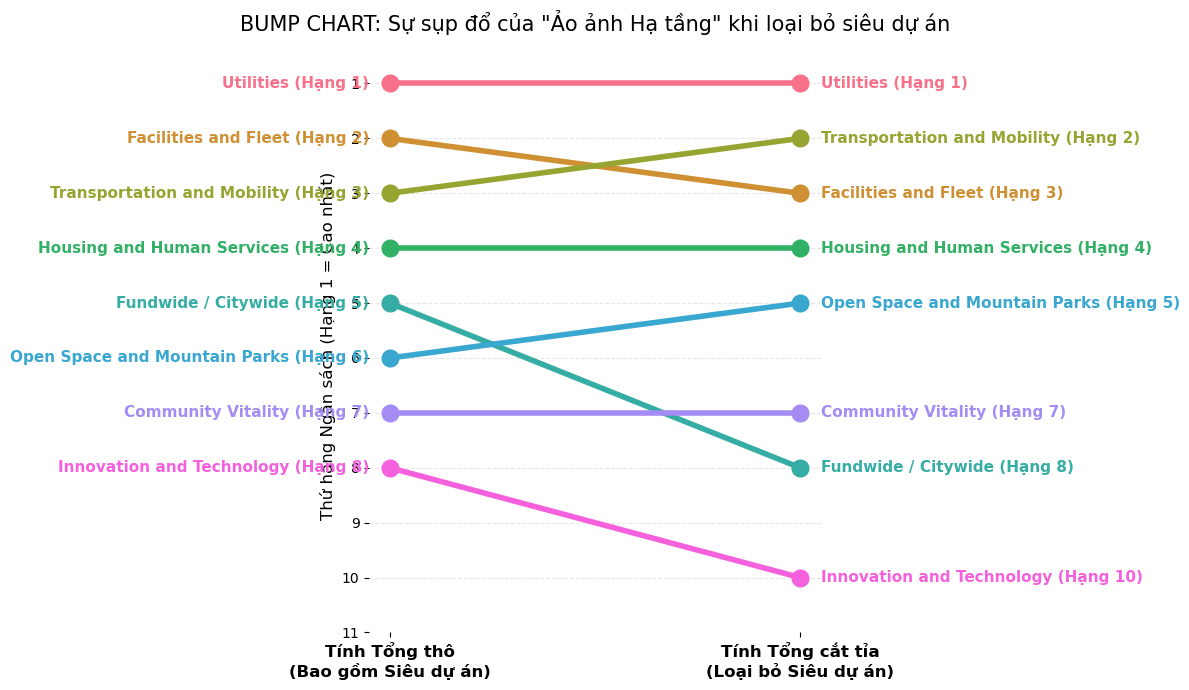

In [16]:
# --- 5. Trực quan hóa sự biến động bằng Bump Chart ---
# Lấy danh sách Top 8 phòng ban dẫn đầu ở kịch bản Base
top_depts = rank_base.head(8).index.tolist()

# Chuẩn bị dataframe lưu thứ hạng của các phòng ban này ở Kịch bản 1 và 2
plot_data = pd.DataFrame({
    'Tính Tổng thô\n(Bao gồm Siêu dự án)': [rank_base.index.get_loc(d) + 1 for d in top_depts],
    'Tính Tổng cắt tỉa\n(Loại bỏ Siêu dự án)': [rank_trimmed.index.get_loc(d) + 1 for d in top_depts]
}, index=top_depts).T

# Tiến hành vẽ biểu đồ
plt.figure(figsize=(12, 7))
colors = sns.color_palette("husl", len(top_depts))

for idx, col in enumerate(plot_data.columns):
    plt.plot(plot_data.index, plot_data[col], marker='o', markersize=12, linewidth=4, 
             color=colors[idx], label=col)
    
    # Ghi chú tên phòng ban ở điểm đầu (trái) và điểm cuối (phải)
    plt.text(-0.05, plot_data[col].iloc[0], f"{col} (Hạng {plot_data[col].iloc[0]})", 
             ha='right', va='center', fontsize=11, fontweight='bold', color=colors[idx])
    plt.text(1.05, plot_data[col].iloc[1], f"{col} (Hạng {plot_data[col].iloc[1]})", 
             ha='left', va='center', fontsize=11, fontweight='bold', color=colors[idx])

plt.gca().invert_yaxis() # Hạng 1 (cao nhất) nằm trên cùng
plt.title('BUMP CHART: Sự sụp đổ của "Ảo ảnh Hạ tầng" khi loại bỏ siêu dự án', fontsize=15, pad=20)
plt.ylabel('Thứ hạng Ngân sách (Hạng 1 = Cao nhất)', fontsize=12)

# Xóa trục X và Y để đồ thị sạch hơn (chỉ để lại các đường lên/xuống)
plt.xticks(fontsize=12, fontweight='bold')
plt.yticks(np.arange(1, max(plot_data.max()) + 2, 1))
plt.grid(True, axis='y', linestyle='--', alpha=0.3)

# Ẩn viền đồ thị
for spine in plt.gca().spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()

### So sánh kịch bản 1 và kịch bản 2
Giữa 2 kịch bản này, ta thấy được một số điều như sau:
- **Sự xáo trộn ở nhóm top 3**: Mặc dù Sở Utilities vẫn giữ vững vị trí số 1, Sở Facilities and Fleet đã bị đẩy từ hạng 2 xuống hạng 3, nhường chỗ cho Sở Transportation and Mobility thăng hạng. Điều này chứng tỏ ngân sách của Sở Facilities and Fleet bị đẩy ngân sách lên bởi các siêu dự án nhiều hơn so với Sở Transportation and Mobility.
- **Những cú trượt dốc mạnh nhất**: Sở Fundwide / Citywide chứng kiến sự tụt hạng nghiêm trọng nhất khi rơi thẳng từ hạng 5 xuống hạng 8. Tương tự, Sở Innovation and Technology cũng bị đẩy từ hạng 8 xuống hạng 10. Dòng tiền của các đơn vị này mang tính giật cục, phụ thuộc cực kỳ lớn vào một vài gói thầu hoặc lần giải ngân khổng lồ.
- **Tính vững của dòng tiền an sinh và cộng đồng**: Các cơ quan phục vụ trực tiếp cho người dân cho thấy một cấu trúc tài chính rất ổn định. Housing and Human Services duy trì vững chắc hạng 4. Open Space and Mountain Parks thậm chí thăng từ hạng 6 lên hạng 5. Sự ổn định này khẳng định ngân sách của họ được giải ngân rải đều qua hàng ngàn hóa đơn nhỏ duy trì hoạt động mỗi ngày thay vì dồn vào các siêu hợp đồng. Điều này thể hiện sự ổn định trong an sinh xã hội ở thành phố Boulder.

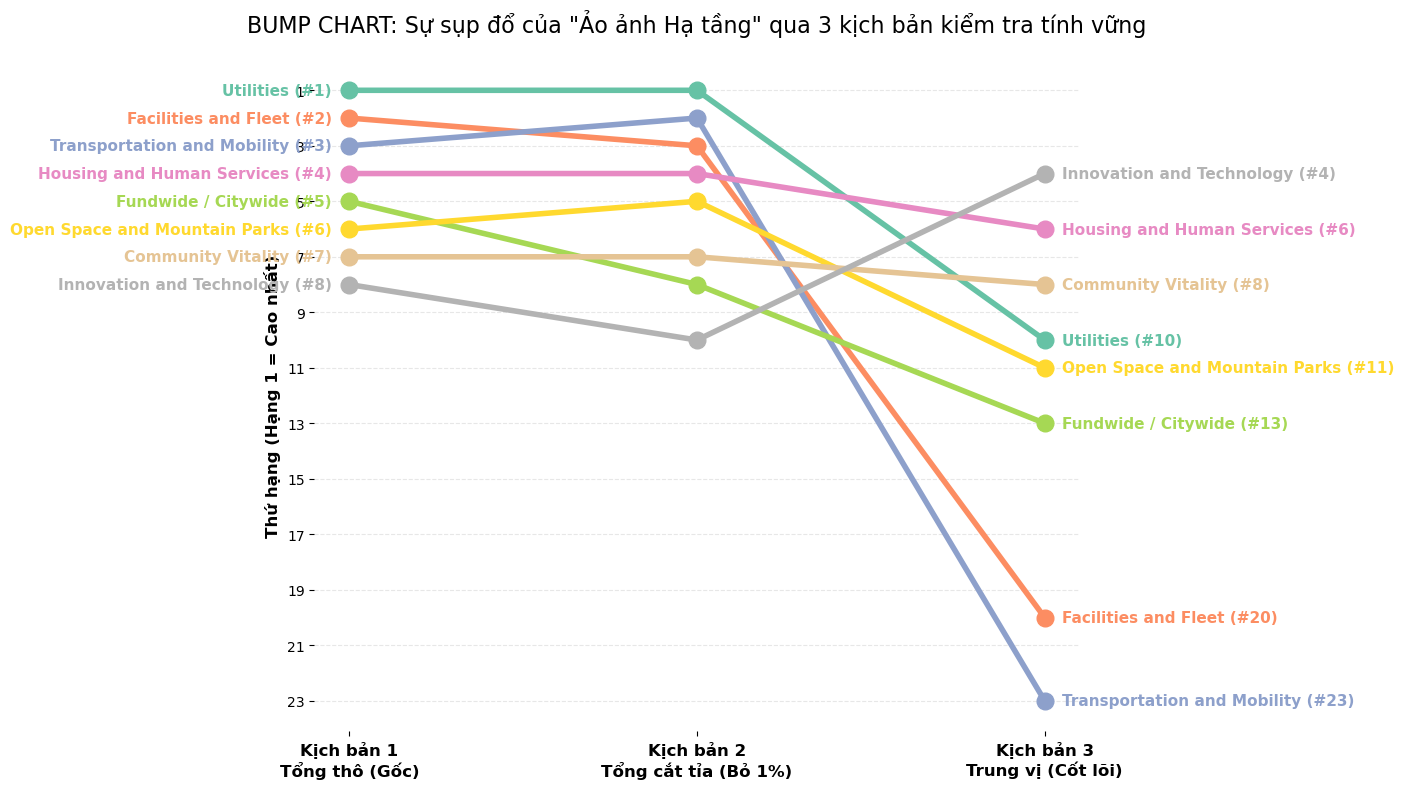

In [17]:
# --- 5. Trực quan hóa sự biến động bằng Bump Chart (Cả 3 kịch bản) ---
# Lấy danh sách Top 8 phòng ban dẫn đầu ở kịch bản Base
top_depts = rank_base.head(8).index.tolist()

# Lấy vị trí thứ hạng của các phòng ban này qua 3 kịch bản
plot_data = pd.DataFrame({
    'Kịch bản 1\nTổng thô (Gốc)': [rank_base.index.get_loc(d) + 1 for d in top_depts],
    'Kịch bản 2\nTổng cắt tỉa (Bỏ 1%)': [rank_trimmed.index.get_loc(d) + 1 for d in top_depts],
    'Kịch bản 3\nTrung vị (Cốt lõi)': [rank_median.index.get_loc(d) + 1 for d in top_depts]
}, index=top_depts).T

# Tiến hành vẽ biểu đồ
plt.figure(figsize=(14, 8))
colors = sns.color_palette("Set2", len(top_depts))

for idx, col in enumerate(plot_data.columns):
    # Vẽ đường nối
    plt.plot(plot_data.index, plot_data[col], marker='o', markersize=12, linewidth=4, 
             color=colors[idx], label=col)
    
    # Ghi chú tên phòng ban ở Kịch bản 1 (bên trái)
    plt.text(-0.05, plot_data[col].iloc[0], f"{col} (#{plot_data[col].iloc[0]})", 
             ha='right', va='center', fontsize=11, fontweight='bold', color=colors[idx])
    
    # Ghi chú tên phòng ban ở Kịch bản 3 (bên phải)
    plt.text(2.05, plot_data[col].iloc[2], f"{col} (#{plot_data[col].iloc[2]})", 
             ha='left', va='center', fontsize=11, fontweight='bold', color=colors[idx])

plt.gca().invert_yaxis() # Hạng 1 (cao nhất) nằm trên cùng
plt.title('BUMP CHART: Sự sụp đổ của "Ảo ảnh Hạ tầng" qua 3 kịch bản kiểm tra tính vững', fontsize=16, pad=20)
plt.ylabel('Thứ hạng (Hạng 1 = Cao nhất)', fontsize=12, fontweight='bold')

# Căn chỉnh trục
plt.xticks(fontsize=12, fontweight='bold')
plt.yticks(np.arange(1, max(plot_data.max()) + 2, 2))
plt.grid(True, axis='y', linestyle='--', alpha=0.3)

# Ẩn viền đồ thị
for spine in plt.gca().spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()

### So sánh kịch bản 1 và kịch bản 3
Giữa 2 kịch bản này, ta có một số các nhận xét sau:
- **Cú rơi tự do của nhóm top 3**: Dù chiếm lĩnh hoàn toàn top 3 ở kịch bản 1 và kịch bản 2, các sở chuyên về xây dựng và hạ tầng đã sụp đổ thứ hạng hoàn toàn khi chuyển sang kịch bản 3. Sở Transportation and Mobility trải qua cú rơi sâu nhất khi rơi thẳng từ hạng 2 xuống tận hạng 23 (đáy bảng). Tương tự, Sở Facilities and Fleet lao dốc từ hạng 3 xuống hạng 20, và Utilities rớt từ hạng 1 xuống hạng 10. Điều này khẳng định chắc nịch bằng toán học: Quyền lực ngân sách của họ hoàn toàn là ảo ảnh được "bơm phồng" bởi một vài siêu dự án, chứ quy mô hóa đơn vận hành mỗi ngày của họ nằm ở mức rất thấp.
- **Sự trỗi dậy của Innovation and Technology**: Ở chiều ngược lại, Sở Innovation and Technology có sự đột phá đáng chú ý. Dù bị đánh tụt xuống tận hạng 10 ở kịch bản 2, cơ quan này lập tức vọt lên chiếm lĩnh vị trí hạng 4 ở kịch bản 3. Điều này chứng tỏ ngân sách của họ tuy không có những hợp đồng "ngàn năm có một" làm bóp méo tổng tiền, nhưng giá trị thanh toán trung vị mỗi ngày cho các dịch vụ công nghệ, phần mềm lại rất cao và đồng đều.
- **Sự bền vững của dòng tiền an sinh**: Các phòng ban như Housing and Human Services và Community Vitality thể hiện sự ổn định tuyệt đối trước mọi phép thử nhiễu. Xuyên suốt cả 3 kịch bản từ đo bằng tổng thô đến trung vị, đường đi của họ gần như nằm ngang, duy trì vững chắc vị thế ở nửa trên của bảng (lần lượt dao động quanh hạng 4-6 và hạng 7-8). Dòng tiền của các cơ quan phục vụ dân sinh này là dòng chảy thực chất, phản ánh đúng nhịp đập tài chính hàng ngày của đô thị.

## Kết luận
Sau khi áp dụng kỹ thuật kiểm tra tính vững (Robustness Check) kết hợp cùng biểu đồ bump chart đối chiếu 3 kịch bản, ta có thể kết luận một số điều như sau về bản chất vận hành ngân sách của thành phố Boulder dựa trên dataset này:
- **Sự sụp đổ của các siêu dự án:** Sự thống trị của các cơ quan như Sở Utilities, Sở Facilities and Fleet, và Sở Transportation and Mobility ở kịch bản 1 (tổng thô) là một kết quả không đáng tin cậy. Quyền lực ngân sách của họ không vững vì nó bị gây nhiễu bởi một số rất ít (chưa tới 1%) các hóa đơn siêu dự án. Khi gạt bỏ các biến nhiễu ngoại lai và nhìn vào quy mô thanh toán cốt lõi (trung vị), nhóm này lập tức "rơi tự do" trên bảng xếp hạng (tiêu biểu là Sở Giao thông rớt thảm hại từ Top 3 xuống tận đáy bảng ở hạng 23).
- **Độ nhạy của dòng tiền giật cục**: Chỉ cần bóc tách đúng 1% số lượng hóa đơn lớn nhất (kịch bản 2 - trimmed sum), thứ hạng đã lập tức có sự xáo trộn. Điều này chứng minh bằng toán học rằng ngân sách của nhiều cơ quan mang tính "giật cục", phụ thuộc cực kỳ lớn vào một vài gói thầu khổng lồ thi thoảng mới xuất hiện chứ không hề có tính phân bổ đều đặn.
- **Quyền lực thực chất thuộc về Khối Vận hành, Công nghệ & An sinh**: Khi loại bỏ các siêu dự án tan đi ở kịch bản 3. Ta thấy được cơ quan Innovation and Technology, Housing and Human Services, và Community Vitality mới chính là những cơ quan nắm giữ dòng chảy tài chính cốt lõi, thanh toán đều đặn với giá trị cao qua hàng ngàn hóa đơn mỗi ngày để duy trì nhịp đập dân sinh của đô thị.